# Встреча 2. План теста — теория

На встрече 1 мы решили, что чекаут стоит тестировать, и получили α и n. Сегодня превращаем их в план теста: что рандомизируем, какой эффект ловим, сколько дней ждём, какие метрики за что отвечают и как сделать тест короче.

| Блок | О чём | Минуты |
|---|---|---|
| 1. Дизайн | единица рандомизации и анализа, одна формула для n и MDE, сплит, длительность, вид теста | 12 |
| 2. Критерии и роли метрик | тип метрики → критерий → ловушка, A/A-проверка, SRM, роли и поправки | 10 |
| 3. Ускорение | стратификация, CUPED, линеаризация, выбросы | 13 |

Числа кейса: конверсия чекаута ≈ 70%, 7 500 пользователей в день, сплит 80/20. Практика — в `practice.ipynb`, полная версия лекции со всеми выводами — в `reference.ipynb`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from statsmodels.stats.proportion import proportion_confint

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'

# Параметры кейса и дизайна по умолчанию (в практике α берём из вердикта встречи 1)
ALPHA, POWER = 0.05, 0.80
P_A, DAILY_USERS, SHARE_B = 0.70, 7_500, 0.20


def z_crit(alpha: float, sides: int) -> float:
    # Критическое значение: z_{1-α} для односторонней альтернативы, z_{1-α/2} для двусторонней
    return stats.norm.ppf(1 - alpha / sides)


def n_total(var_a: float, var_b: float, mde: float, share_b: float = SHARE_B,
            alpha: float = ALPHA, power: float = POWER, sides: int = 2) -> int:
    # Общий размер выборки (обе группы) при доле трафика share_b в группе B
    z = z_crit(alpha, sides) + stats.norm.ppf(power)
    return int(np.ceil(z ** 2 / mde ** 2 * (var_a / (1 - share_b) + var_b / share_b)))


def mde_for(n: int, var: float, share_b: float = SHARE_B,
            alpha: float = ALPHA, power: float = POWER, sides: int = 2) -> float:
    # Та же формула, решённая относительно эффекта (дисперсии групп считаем равными)
    z = z_crit(alpha, sides) + stats.norm.ppf(power)
    return z * np.sqrt(var / ((1 - share_b) * n) + var / (share_b * n))


def masked_mean_var(x: np.ndarray, mask: np.ndarray):
    # Среднее, дисперсия и размер по строкам x только по наблюдениям из mask
    n = mask.sum(axis=1)
    mean = (x * mask).sum(axis=1) / n
    var = ((x ** 2 * mask).sum(axis=1) - n * mean ** 2) / (n - 1)
    return mean, var, n


def z_pvalue(delta: np.ndarray, se: np.ndarray) -> np.ndarray:
    return 2 * stats.norm.sf(np.abs(delta / se))


def rate_with_ci(rejected: np.ndarray):
    low, high = proportion_confint(rejected.sum(), rejected.size, method='wilson')
    return float(rejected.mean()), float(low), float(high)


def plot_rates(ax, rates: dict, title: str, reference: float | None = ALPHA) -> None:
    # Доли отклонений H0 с 95% ДИ: одна точка на метод
    names = list(rates)[::-1]
    values = np.array([rate_with_ci(rates[name]) for name in names])
    ax.errorbar(values[:, 0], names, xerr=[values[:, 0] - values[:, 1], values[:, 2] - values[:, 0]],
                fmt='o', color=BLUE, capsize=4)
    if reference is not None:
        ax.axvline(reference, color=RED, linestyle='--', label=f'Заявленный уровень {reference:.0%}')
        ax.legend(loc='lower right')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.set_title(title)

## Блок 1. Дизайн: единица, MDE, размер выборки, длительность

### Единица рандомизации и единица анализа

* **Единица рандомизации** — то, на что мы «бросаем монетку». В чекауте это пользователь: группа = хеш(`user_id` + соль теста).
* **Единица анализа** — то, по чему считаем метрику и её дисперсию.

Если они совпадают, наблюдения независимы и работают обычные z- и t-тесты. Если нет — дисперсия считается неверно. Пример: **средний чек** = Σ выручки / Σ заказов. Рандомизируем пользователей, а наблюдение — заказ. Заказы одного пользователя похожи, поэтому наивная SE «по заказам» занижена и тест врёт. Лечится дельта-методом или линеаризацией (блок 3). Если рандомизировать можно только крупнее — магазин, город, интервал времени, — это кластерный дизайн, встреча 5.

В дизайн-доке пишем обе единицы явно.

### Одна формула для n и MDE

Пусть $w_A$, $w_B = 1 - w_A$ — доли трафика, $\sigma_A^2$, $\sigma_B^2$ — дисперсии метрики на пользователя, $\delta$ — абсолютный эффект, $s$ — **сторонность** альтернативы ($s = 1$ или $s = 2$). Тогда общий размер выборки

$$
N = \frac{\left(z_{1-\alpha/s} + z_{1-\beta}\right)^2}{\delta^2}\left(\frac{\sigma_A^2}{w_A} + \frac{\sigma_B^2}{w_B}\right),
$$

а MDE — та же формула, решённая относительно $\delta$ при заданном $N$:

$$
\text{MDE} = \left(z_{1-\alpha/s} + z_{1-\beta}\right)\sqrt{\frac{\sigma_A^2}{w_A N} + \frac{\sigma_B^2}{w_B N}}.
$$

Для конверсии $\sigma^2 = p(1-p)$. Сторонность — решение дизайна, а не деталь формулы: считать MDE с $z_{1-\alpha}$, а $n$ с $z_{1-\alpha/2}$ — значит описывать два разных теста.

Посчитаем цену решений для чекаута и проверим формулу симуляцией: число конверсий в группе — $\mathrm{Binomial}(n_g, p_g)$, поэтому тысячи тестов считаются мгновенно.

,N,дней трафика,недель
вариант,,,
"базовый: +1 п.п., двусторонний, 80/20",101408,14,2
относительный MDE: +1% (= +0.7 п.п.),207957,28,4
односторонняя альтернатива,79879,11,2
сплит 50/50,65287,9,2


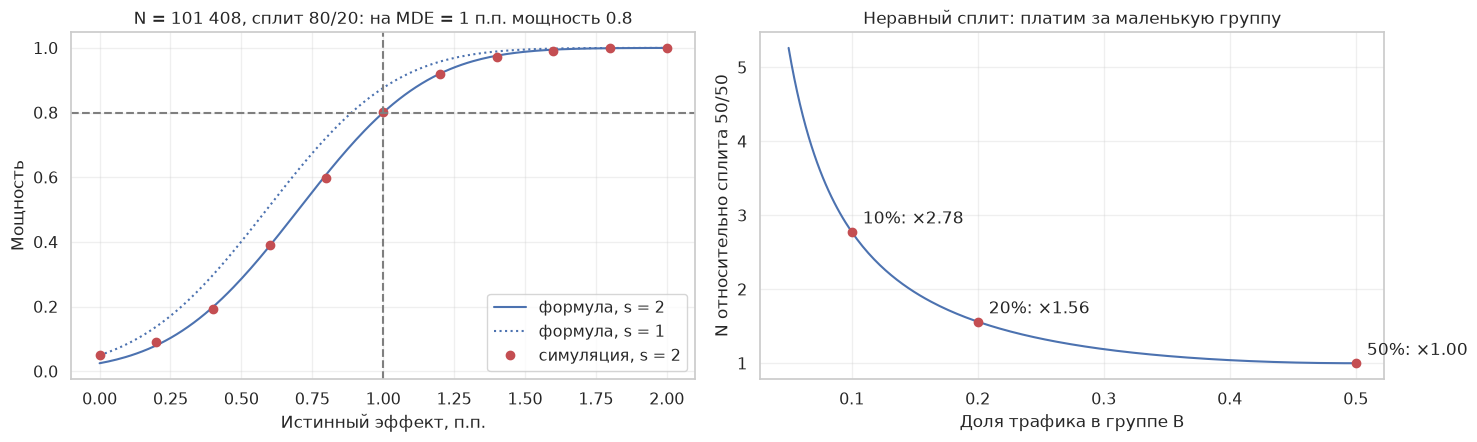

In [2]:
variants = {
    'базовый: +1 п.п., двусторонний, 80/20': dict(mde=0.010),
    'относительный MDE: +1% (= +0.7 п.п.)': dict(mde=0.007),
    'односторонняя альтернатива': dict(mde=0.010, sides=1),
    'сплит 50/50': dict(mde=0.010, share_b=0.5),
}
rows = []
for name, params in variants.items():
    mde = params['mde']
    n = n_total(P_A * (1 - P_A), (P_A + mde) * (1 - P_A - mde), **params)
    days = int(np.ceil(n / DAILY_USERS))
    rows.append({'вариант': name, 'N': n, 'дней трафика': days, 'недель': int(np.ceil(days / 7))})
design = pd.DataFrame(rows).set_index('вариант')
display(design)

# Симуляция мощности для базового дизайна
N_BASE = design['N'].iloc[0]
n_b = round(N_BASE * SHARE_B)
n_a = N_BASE - n_b
rng = np.random.default_rng(2)
effects = np.linspace(0, 0.02, 11)
sim_power = []
for d in effects:
    x_a, x_b = rng.binomial(n_a, P_A, 4_000), rng.binomial(n_b, P_A + d, 4_000)
    p_pool = (x_a + x_b) / N_BASE
    z = (x_b / n_b - x_a / n_a) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    sim_power.append(np.mean(np.abs(z) > z_crit(ALPHA, 2)))
grid = np.linspace(0, 0.02, 200)
se = np.sqrt(P_A * (1 - P_A) / n_a + (P_A + grid) * (1 - P_A - grid) / n_b)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(grid * 100, stats.norm.sf(z_crit(ALPHA, 2) - grid / se), color=BLUE, label='формула, s = 2')
axes[0].plot(grid * 100, stats.norm.sf(z_crit(ALPHA, 1) - grid / se), color=BLUE, ls=':', label='формула, s = 1')
axes[0].plot(effects * 100, sim_power, 'o', color=RED, label='симуляция, s = 2')
axes[0].axhline(POWER, color=GRAY, ls='--')
axes[0].axvline(1.0, color=GRAY, ls='--')
axes[0].set_xlabel('Истинный эффект, п.п.')
axes[0].set_ylabel('Мощность')
axes[0].set_title(f'N = {N_BASE:,}'.replace(',', ' ') + ', сплит 80/20: на MDE = 1 п.п. мощность 0.8')
axes[0].legend(loc='lower right')

shares = np.linspace(0.05, 0.5, 200)
cost = (1 / shares + 1 / (1 - shares)) / 4
axes[1].plot(shares, cost, color=BLUE)
for w in (0.1, 0.2, 0.5):
    c = (1 / w + 1 / (1 - w)) / 4
    axes[1].scatter([w], [c], color=RED, zorder=3)
    axes[1].annotate(f'{w:.0%}: ×{c:.2f}', (w, c), textcoords='offset points', xytext=(8, 6))
axes[1].set_xlabel('Доля трафика в группе B')
axes[1].set_ylabel('N относительно сплита 50/50')
axes[1].set_title('Неравный сплит: платим за маленькую группу')
plt.tight_layout()
plt.show()

Что видно:

* **Абсолютный или относительный MDE.** «+1%» — это либо +1 п.п. (70% → 71%), либо +1% от 70% (70% → 70.7%). $N \propto 1/\delta^2$, поэтому относительная трактовка требует в $(1/0.7)^2 \approx 2$ раза больше трафика. Уточняем у заказчика и пишем в доке и число, и единицы.
* **Неравный сплит.** $N \propto 1/w_A + 1/w_B$: 4 при 50/50 и 6.25 при 80/20, то есть ×1.56. Это цена осторожности: 14 дней вместо 9.
* **Сторонность.** Односторонний тест дешевле на ≈21%, но не видит ухудшения. Если вопрос «есть ли эффект» — двусторонний. Если решение денежное, как на встрече 1, — односторонний против $\theta_{BE}$ (ниже). Guardrail — односторонние non-inferiority.
* **Длительность** округляем вверх до целых недель: в будни и выходные покупают разные люди. Минимум — 1–2 недели, даже если $N$ набирается за 3 дня. Длительность фиксируем до старта; подглядывание и досрочная остановка — встреча 4.
* Точки симуляции легли на кривую: нормальная аппроксимация для конверсии 70% при таких $N$ работает.

### Что доказываем: вид теста

$\mu$ — истинная разность «B − A» (для метрик «меньше — лучше» знаки меняются).

| Вид | $H_0$ | $H_1$ | Когда |
|---|---|---|---|
| Superiority | $\mu \le 0$ (двусторонний: $\mu = 0$) | $\mu > 0$ ($\mu \ne 0$) | новое лучше; граница гипотезы — **ноль** |
| Non-inferiority | $\mu \le -\Delta$ | $\mu > -\Delta$ | guardrail: хуже не более чем на допуск $\Delta$ |
| Equivalence | $\lvert\mu\rvert \ge \Delta$ | $\lvert\mu\rvert < \Delta$ | миграция, рефакторинг: «ничего не изменилось», TOST |
| Против порога безубыточности | $\mu \le \theta_{BE}$ | $\mu > \theta_{BE}$ | внедрение окупается; $\theta_{BE}$ — из финмодели встречи 1 |

Три разных числа не путаем:

* **MDE** — параметр мощности: эффект, который тест заметит с вероятностью $1 - \beta$. В гипотезу он не входит.
* **$\Delta$** — допуск non-inferiority и equivalence: насколько хуже ещё приемлемо.
* **$\theta_{BE}$** — граница гипотезы, если решаем «окупится ли». Тогда $n$ считается под $\text{MDE} - \theta_{BE}$. В кейсе чекаута встреча 1 выбрала α = 0.5 против $\theta_{BE} = 0.246$ п.п.: внедряем, если оценка выше порога. Такой тест на 105 тыс. пользователей видит 0.54 п.п. — втрое дешевле стандартного теста против нуля на тот же эффект (практика, задание 1).

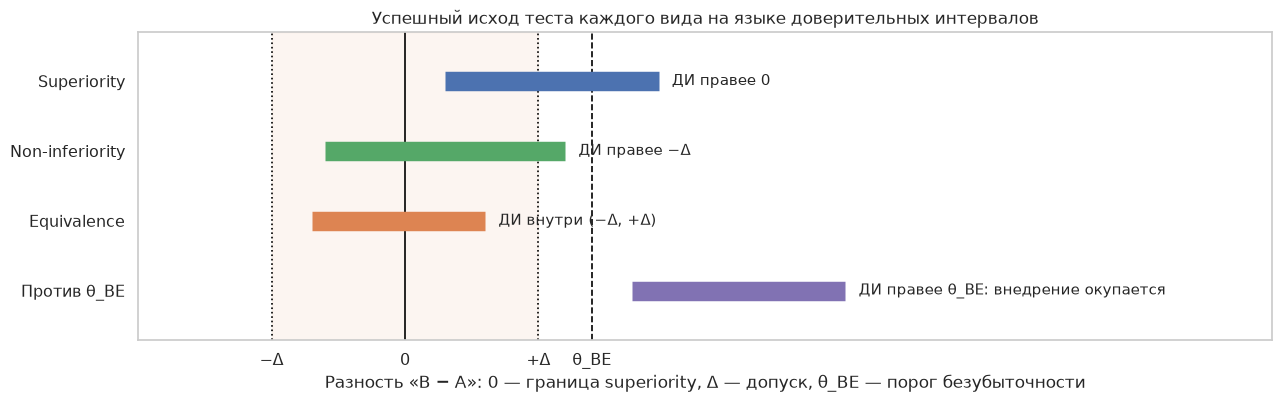

In [3]:
margin, theta_be = 1.0, 1.4
examples = [
    ('Против θ_BE', (1.7, 3.3), PURPLE, 'ДИ правее θ_BE: внедрение окупается'),
    ('Equivalence', (-0.7, 0.6), ORANGE, 'ДИ внутри (−Δ, +Δ)'),
    ('Non-inferiority', (-0.6, 1.2), GREEN, 'ДИ правее −Δ'),
    ('Superiority', (0.3, 1.9), BLUE, 'ДИ правее 0'),
]
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.axvspan(-margin, margin, color=ORANGE, alpha=0.08)
for x, style in ((-margin, ':'), (0, '-'), (margin, ':'), (theta_be, '--')):
    ax.axvline(x, color='black', linestyle=style, linewidth=1.2)
for row, (name, (left, right), color, note) in enumerate(examples):
    ax.plot([left, right], [row, row], color=color, linewidth=14, solid_capstyle='butt')
    ax.text(right + 0.1, row, note, va='center', fontsize=11)
ax.set_yticks(range(len(examples)), labels=[e[0] for e in examples])
ax.set_xticks([-margin, 0, margin, theta_be], labels=['−Δ', '0', '+Δ', 'θ_BE'])
ax.set_xlabel('Разность «B − A»: 0 — граница superiority, Δ — допуск, θ_BE — порог безубыточности')
ax.set_xlim(-2, 6.5)
ax.set_ylim(-0.7, len(examples) - 0.3)
ax.grid(False)
ax.set_title('Успешный исход теста каждого вида на языке доверительных интервалов')
plt.tight_layout()
plt.show()

## Блок 2. Критерии и роли метрик

### Тип метрики → критерий → ловушка

| Тип метрики | Пример в чекауте | Критерий | Ловушка |
|---|---|---|---|
| Доля пользователей | конверсия, доля ошибок оплаты | z-тест для двух долей (≡ χ² 2×2) | считать по сессиям или заказам, когда рандомизируем пользователей |
| Среднее на пользователя | ARPU, время на чекауте | t-тест Уэлча (≈ z при больших n) | тяжёлый хвост: «n > 30» ничего не гарантирует; выбросы — блок 3 |
| Отношение сумм | средний чек, CTR | дельта-метод или линеаризация + t-тест | наивный тест «по заказам» даёт α ≈ 19% (блок 3) |
| Квантиль | медиана времени на чекауте | бутстреп по пользователям | бутстреп по заказам внутри пользователя; медиана денег ≠ среднее денег |
| Распределение | любая непрерывная | Манн–Уитни | проверяет $P(X_B > X_A) \ne 1/2$, а не средние: значимый U ≠ рост выручки |
| Доли групп | 80/20 в логе | χ² на согласие (SRM) | смотреть эффекты раньше, чем SRM (встреча 3) |

Любой критерий проверяется одинаково: **A/A-симуляция на своих данных** даёт долю ложных срабатываний ≈ α, A/B с подмешанным эффектом — заложенную мощность. Проверим так правило «n > 30» на выручке: 70% пользователей покупают, чек логнормальный, сплит 80/20, эффекта нет.

                                         α факт  левый хвост  правый хвост
данные                            N                                       
хвост как в чекауте (σ_log = 0.8) 50      0.088        0.078         0.010
                                  200     0.067        0.056         0.011
                                  1000    0.053        0.038         0.015
                                  5000    0.051        0.031         0.020
                                  20000   0.049        0.026         0.022
тяжёлый хвост (σ_log = 2.0)       50      0.082        0.081         0.001
                                  200     0.089        0.088         0.001
                                  1000    0.079        0.078         0.002
                                  5000    0.071        0.067         0.003
                                  20000   0.061        0.054         0.006


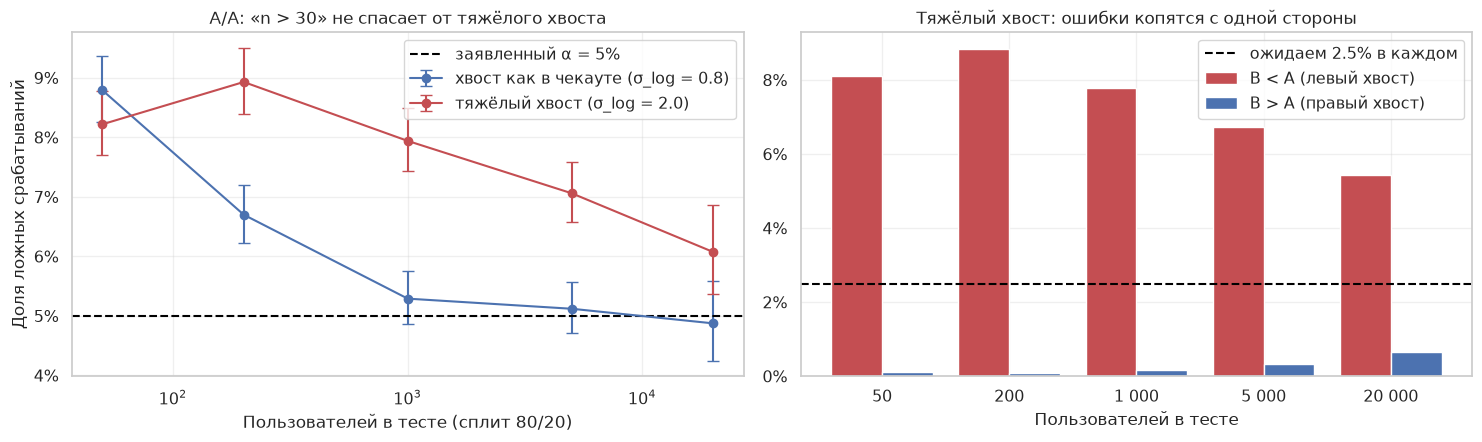

In [4]:
def revenue(rng, size, sigma):
    # Выручка пользователя: покупка с вероятностью 0.7, чек логнормальный
    return (rng.random(size) < 0.7) * rng.lognormal(7.8, sigma, size)


def aa_welch(n_total_users: int, sigma: float, n_sim: int, rng, batch: int = 2_000):
    # Доля отклонений H0 двусторонним тестом Уэлча и доля z > 0 среди них
    n_b = n_total_users // 5
    n_a = n_total_users - n_b
    z_all = []
    for _ in range(n_sim // batch):
        a, b = revenue(rng, (batch, n_a), sigma), revenue(rng, (batch, n_b), sigma)
        se = np.sqrt(a.var(axis=1, ddof=1) / n_a + b.var(axis=1, ddof=1) / n_b)
        z_all.append((b.mean(axis=1) - a.mean(axis=1)) / se)
    z = np.concatenate(z_all)
    crit = z_crit(ALPHA, 2)
    return np.abs(z) > crit, z < -crit, z > crit


rng = np.random.default_rng(11)
sizes = [50, 200, 1_000, 5_000, 20_000]
tails = {'хвост как в чекауте (σ_log = 0.8)': 0.8, 'тяжёлый хвост (σ_log = 2.0)': 2.0}
aa_rows, aa_rates = [], {}
for label, sigma in tails.items():
    for n in sizes:
        n_sim = 10_000 if n <= 5_000 else 4_000
        rejected, left, right = aa_welch(n, sigma, n_sim, rng, batch=min(2_000, 40_000_000 // n))
        aa_rates[(label, n)] = rejected
        aa_rows.append({'данные': label, 'N': n, 'α факт': rejected.mean(),
                        'левый хвост': left.mean(), 'правый хвост': right.mean()})
aa_table = pd.DataFrame(aa_rows).set_index(['данные', 'N'])
print(aa_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for (label, sigma), color in zip(tails.items(), (BLUE, RED)):
    vals = np.array([rate_with_ci(aa_rates[(label, n)]) for n in sizes])
    axes[0].errorbar(sizes, vals[:, 0], yerr=[vals[:, 0] - vals[:, 1], vals[:, 2] - vals[:, 0]],
                     fmt='o-', color=color, capsize=4, label=label)
axes[0].axhline(ALPHA, color='black', ls='--', label='заявленный α = 5%')
axes[0].set_xscale('log')
axes[0].set_xlabel('Пользователей в тесте (сплит 80/20)')
axes[0].set_ylabel('Доля ложных срабатываний')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[0].set_title('A/A: «n > 30» не спасает от тяжёлого хвоста')
axes[0].legend()
heavy = aa_table.loc['тяжёлый хвост (σ_log = 2.0)']
x = np.arange(len(sizes))
axes[1].bar(x - 0.2, heavy['левый хвост'], 0.4, color=RED, label='B < A (левый хвост)')
axes[1].bar(x + 0.2, heavy['правый хвост'], 0.4, color=BLUE, label='B > A (правый хвост)')
axes[1].axhline(ALPHA / 2, color='black', ls='--', label='ожидаем 2.5% в каждом')
axes[1].set_xticks(x, labels=[f'{n:,}'.replace(',', ' ') for n in sizes])
axes[1].set_xlabel('Пользователей в тесте')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].set_title('Тяжёлый хвост: ошибки копятся с одной стороны')
axes[1].legend()
plt.tight_layout()
plt.show()

Даже с хвостом как у нашей выручки на 50 пользователях α ≈ 9%; к тысяче тест Уэлча выходит на 5%. С тяжёлым хвостом α завышен и на 20 тыс. пользователей, и почти все ошибки — в одну сторону: маленькая группа B редко ловит «кита», и её среднее чаще занижено. Для одностороннего guardrail это худший случай. Правило «n > 30» выросло из нормальных данных; на своих данных α проверяют A/A-симуляцией (практика, задание 2).

### χ² на согласие — это проверка SRM

Тот же χ², только сравниваем наблюдаемые размеры групп с заложенным сплитом. Отклонение долей (Sample Ratio Mismatch) значит, что сломано назначение или логирование, и эффектам верить нельзя.

In [5]:
for observed in ([84_700, 21_300], [84_000, 22_000]):
    total = sum(observed)
    expected = [total * (1 - SHARE_B), total * SHARE_B]
    chi2, p = stats.chisquare(observed, expected)
    a_txt, b_txt = (f'{v:,}'.replace(',', ' ') for v in observed)
    print(f'A = {a_txt}, B = {b_txt}: доля B = {observed[1] / total:.2%}, χ² = {chi2:5.1f}, p = {p:.1e}')

A = 84 700, B = 21 300: доля B = 20.09%, χ² =   0.6, p = 4.4e-01
A = 84 000, B = 22 000: доля B = 20.75%, χ² =  37.7, p = 8.1e-10


Доля B 20.75% вместо 20% выглядит мелочью, но на 106 тыс. пользователей это p ≈ 10⁻⁹. Порог SRM обычно строгий — p < 0.001, — потому что проверка идёт до всего остального. Причины SRM и что с ним делать — встреча 3.

### Роли метрик

Цель бизнеса — чтобы пользователи покупали больше и дольше. Её **долгосрочная метрика** (north star) — заказы и выручка на пользователя за 28 дней и дальше. Дождаться её в тесте нельзя, поэтому у метрик теста разные роли. Классификация — по тому, **что мы с метрикой делаем** ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)):

* **Метрики качества данных.** Можно ли вообще доверять эксперименту: SRM, дубли, пользователи в обеих группах, потери телеметрии (встреча 3).
* **OEC (Overall Evaluation Criterion).** Метрика, по которой решаем, запускать ли изменение. Измеряется за время теста, но должна указывать на долгосрочную ценность. Идеально — одна. В кейсе это конверсия чекаута в заказ.
* **Guardrail-метрики.** Не должны заметно ухудшиться, даже если OEC растёт: доля ошибок оплаты.
* **Локальные и диагностические метрики.** Объясняют, откуда взялось движение OEC, но решения не принимают: ARPU, время на чекауте, средний чек.

Порядок чтения результата следует из ролей: сначала данным можно верить, потом OEC, потом «ничего не сломали», и только потом «почему».

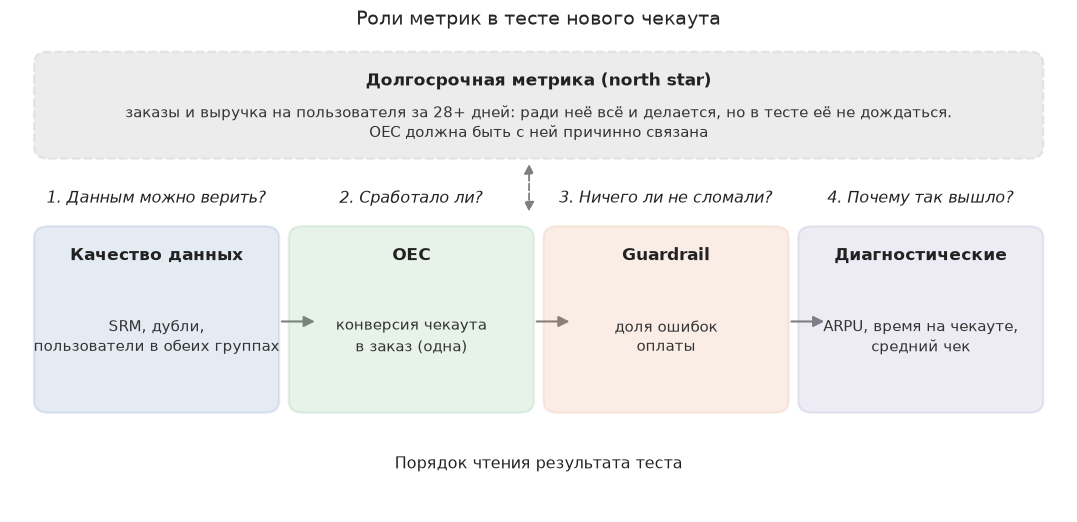

In [6]:
def draw_roles():
    fig, ax = plt.subplots(figsize=(11, 5.4))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 6)
    ax.axis('off')

    def box(x, y, w, h, title, body, color, dashed=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color,
                                    edgecolor=GRAY if dashed else color, alpha=.14, linewidth=1.6,
                                    linestyle='--' if dashed else '-'))
        ax.text(x + w / 2, y + h - .32, title, ha='center', va='center', fontsize=12.5, fontweight='bold', color='#222222')
        ax.text(x + w / 2, y + h / 2 - .22, body, ha='center', va='center', fontsize=10.5, color='#333333', linespacing=1.35)

    box(.3, 4.5, 10.4, 1.25, 'Долгосрочная метрика (north star)',
        'заказы и выручка на пользователя за 28+ дней: ради неё всё и делается, но в тесте её не дождаться.\n'
        'OEC должна быть с ней причинно связана', GRAY, dashed=True)
    steps = [
        (.3, 'Данным можно верить?', 'Качество данных', 'SRM, дубли,\nпользователи в обеих группах', BLUE),
        (2.95, 'Сработало ли?', 'OEC', 'конверсия чекаута\nв заказ (одна)', GREEN),
        (5.6, 'Ничего ли не сломали?', 'Guardrail', 'доля ошибок\nоплаты', ORANGE),
        (8.25, 'Почему так вышло?', 'Диагностические', 'ARPU, время на чекауте,\nсредний чек', PURPLE),
    ]
    for k, (x, question, title, body, color) in enumerate(steps):
        ax.text(x + 1.225, 3.95, f'{k + 1}. {question}', ha='center', va='center', fontsize=11.5, color='#222222', style='italic')
        box(x, 1.3, 2.45, 2.25, title, body, color)
        if k < 3:
            ax.add_patch(FancyArrowPatch((x + 2.5, 2.4), (x + 2.9, 2.4), arrowstyle='-|>', mutation_scale=16, color=GRAY, linewidth=1.5))
    ax.add_patch(FancyArrowPatch((5.4, 3.75), (5.4, 4.42), arrowstyle='<|-|>', mutation_scale=14, color=GRAY, linewidth=1.3, linestyle='--'))
    ax.text(5.5, .55, 'Порядок чтения результата теста', ha='center', fontsize=11.5, color='#222222')
    ax.set_title('Роли метрик в тесте нового чекаута', fontsize=14, pad=8)
    plt.tight_layout()
    plt.show()


draw_roles()

### Разные метрики тестируются по-разному

Поправка на множественность следует из **правила запуска**, а не навешивается на все метрики одинаково (фреймворк Spotify, [Schultzberg и др., 2024](https://arxiv.org/abs/2402.11609); сегменты и множественность при анализе — встреча 6).

* **Основная метрика (OEC / success)** — одна, поэтому тестируем без поправки. Если success-метрик $S$ и достаточно одной, α делим на $S$.
* **Вторичные (диагностические)** — заранее определённое «семейство»: если их много, «хотя бы одна» почти наверняка выстрелит случайно, поэтому поправка (например, Холма) по семейству.
* **Guardrail** — односторонний non-inferiority без поправки на α: условие «все должны пройти» не накапливает α, но снижает мощность. Поэтому поправляют β: каждый guardrail считают на мощность $1 - \frac{\beta}{G+1}$, где $G$ — число guardrail.

| Роль | Что проверяем | Правило запуска | Уровень значимости |
|---|---|---|---|
| Основная (OEC / success) | superiority | одна метрика | α, без поправки |
| Вторичные (диагностические) | superiority | «хотя бы одна» как объяснение | α с поправкой по семейству |
| Guardrail | non-inferiority | «все значимо не хуже» | односторонний, α без поправки; мощность $1 - \beta/(G+1)$ |

## Блок 3. Ускорение: меньше дисперсия — короче тест

В формуле из блока 1 $N \propto \sigma^2$. Снизили дисперсию на 37% — тест короче на 37% при тех же α, мощности и MDE. Четыре рабочих инструмента:

| Метод | Что делает | Что нужно |
|---|---|---|
| Стратификация | убирает дисперсию между сегментами | сегменты, известные до теста |
| CUPED | вычитает часть метрики, объяснимую ковариатой | ковариата, не зависящая от воздействия (обычно предпериод) |
| Линеаризация | **сама не снижает дисперсию**: делает метрику отношения пользовательской | числитель и знаменатель по пользователям |
| Работа с выбросами | ограничивает влияние экстремальных значений | порог, не зависящий от воздействия |

Что ещё бывает: VWE (веса по шумности пользователя), CUPAC и MLRATE (ковариата из ML-модели), бакетизация (ускоряет расчёты, а не тест).

### [Стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/)

Дисперсия раскладывается на «внутри страт» и «между стратами»:

$$
\sigma^2 = \sum_k w_k \sigma_k^2 + \sum_k w_k (\mu_k - \mu)^2 .
$$

Стратификация убирает второе слагаемое. Сравним четыре схемы на двух равных стратах со средними 2000 и 3000: случайные группы; **стратифицированное сэмплирование** (доли страт в группах фиксированы) с обычным и со **стратифицированным средним** $\bar Y_{strat} = \sum_k w_k \bar Y_k$; **постстратификация** (группы случайные, среднее стратифицированное).

Дисперсия: 640,625 = 390,625 (внутри страт) + 250,000 (между стратами)
Расчётный объём выборки на группу: 1006



                                       Ошибка I рода  Мощность  SD оценки  Средняя SE
Случайно, обычное среднее                      0.048     0.791     35.674      35.674
Страт. сэмплирование, обычное среднее          0.012     0.854     27.518      35.685
Страт. сэмплирование, страт. среднее           0.054     0.952     28.241      27.878
Постстратификация                              0.052     0.946     28.013      27.862


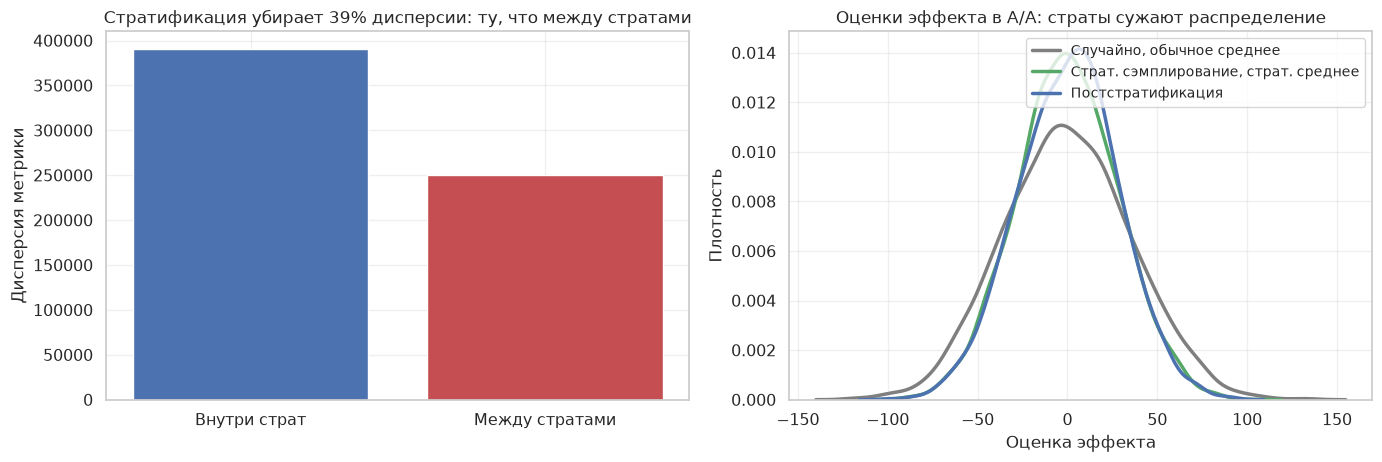

In [7]:
STRAT_CONFIG = {
    "alpha": ALPHA,
    "beta": 0.2,
    "effect": 100.0,
    "weights": (0.5, 0.5),  # доли страт в популяции
    "means": (2_000.0, 3_000.0),
    "stds": (625.0, 625.0),
}
strat_weights = np.array(STRAT_CONFIG["weights"])
strat_means = np.array(STRAT_CONFIG["means"])
strat_stds = np.array(STRAT_CONFIG["stds"])

# Общая дисперсия метрики: среднее дисперсий внутри страт + разброс средних между стратами
overall_mean = strat_weights @ strat_means
var_within = strat_weights @ strat_stds ** 2
var_between = strat_weights @ (strat_means - overall_mean) ** 2
var_total = var_within + var_between

z_sum = stats.norm.ppf(1 - STRAT_CONFIG["alpha"] / 2) + stats.norm.ppf(1 - STRAT_CONFIG["beta"])
strat_sample_size = int(np.ceil(2 * z_sum ** 2 * var_total / STRAT_CONFIG["effect"] ** 2))
print(f'Дисперсия: {var_total:,.0f} = {var_within:,.0f} (внутри страт) + {var_between:,.0f} (между стратами)')
print(f'Расчётный объём выборки на группу: {strat_sample_size}\n')


def generate_group(rng: np.random.Generator, size: tuple[int, int], stratified: bool, effect: float = 0.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует метрику и принадлежность к первой страте для группы с фиксированными или случайными долями страт."""
    if stratified:
        in_first = np.broadcast_to(np.arange(size[1]) < round(size[1] * strat_weights[0]), size)
    else:
        in_first = rng.random(size) < strat_weights[0]
    means = np.where(in_first, strat_means[0], strat_means[1])
    stds = np.where(in_first, strat_stds[0], strat_stds[1])
    return rng.normal(means + effect, stds), in_first


def plain_estimate(y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает обычное среднее и выборочную дисперсию метрики."""
    return y.mean(axis=1), y.var(axis=1, ddof=1)


def strat_estimate(y: np.ndarray, in_first: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Возвращает стратифицированное среднее и взвешенную дисперсию внутри страт."""
    mean_one, var_one, _ = masked_mean_var(y, in_first)
    mean_two, var_two, _ = masked_mean_var(y, ~in_first)
    return (strat_weights[0] * mean_one + strat_weights[1] * mean_two,
            strat_weights[0] * var_one + strat_weights[1] * var_two)


def simulate_strat(n: int, n_simulations: int = 4_000, batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Сравнивает способы формирования групп и оценки среднего на A/A и A/B."""
    rng = np.random.default_rng(42)
    # Название: (стратифицированное сэмплирование, стратифицированное среднее)
    schemes = {
        'Случайно, обычное среднее': (False, False),
        'Страт. сэмплирование, обычное среднее': (True, False),
        'Страт. сэмплирование, страт. среднее': (True, True),
        'Постстратификация': (False, True),
    }
    result = {name: {'aa': [], 'ab': [], 'delta': [], 'se': []} for name in schemes}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', STRAT_CONFIG['effect'])):
            for name, (stratified, use_strat_mean) in schemes.items():
                y_c, first_c = generate_group(rng, (batch, n), stratified)
                y_t, first_t = generate_group(rng, (batch, n), stratified, effect)
                mean_c, var_c = strat_estimate(y_c, first_c) if use_strat_mean else plain_estimate(y_c)
                mean_t, var_t = strat_estimate(y_t, first_t) if use_strat_mean else plain_estimate(y_t)
                delta, se = mean_t - mean_c, np.sqrt((var_c + var_t) / n)
                result[name][key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'aa':
                    result[name]['delta'].append(delta)
                    result[name]['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


strat_results = simulate_strat(strat_sample_size)
print(pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in strat_results.items()
}).T.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(['Внутри страт', 'Между стратами'], [var_within, var_between], color=[BLUE, RED])
axes[0].set_title(f'Стратификация убирает {var_between / var_total:.0%} дисперсии: ту, что между стратами')
axes[0].set_ylabel('Дисперсия метрики')
styles = {'Случайно, обычное среднее': GRAY, 'Страт. сэмплирование, страт. среднее': GREEN, 'Постстратификация': BLUE}
for name, color in styles.items():
    sns.kdeplot(strat_results[name]['delta'], ax=axes[1], label=name, color=color, linewidth=2.5)
axes[1].set_title('Оценки эффекта в A/A: страты сужают распределение')
axes[1].set_xlabel('Оценка эффекта')
axes[1].set_ylabel('Плотность')
axes[1].legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()

* **Стратифицированное сэмплирование без стратифицированного среднего** сломано: оценка стала точнее (SD ≈ 27.5), но тест считает SE как для случайных групп (≈ 35.7). Ошибка I рода ≈ 1% вместо 5% — мощность потеряна впустую.
* **Стратифицированное среднее** возвращает α к 5% и поднимает мощность с ≈ 0.79 до ≈ 0.95.
* **Постстратификация** почти не уступает: плата за случайный состав групп — порядка $1/n^2$, выигрыш — порядка $1/n$. Страты определяем **до** теста, а воздействие не должно переводить пользователя из страты в страту.

### [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/)

CUPED ([Deng et al., 2013](https://doi.org/10.1145/2433396.2433413)) заменяет метрику $Y$ на

$$
Y_{cuped} = Y - \theta\,(X - \bar X), \qquad \theta = \frac{\mathrm{cov}(Y, X)}{\mathbb{V}(X)},
$$

где $X$ — ковариата до теста (чаще всего та же метрика на предпериоде), $\theta$ и $\bar X$ — общие для обеих групп. В обеих группах в среднем вычитается одно и то же, поэтому эффект не смещается, а дисперсия падает до $\mathbb{V}(Y)(1 - \rho^2)$. Выборка сокращается в $1/(1-\rho^2)$ раз.

Проверим на 2 000 симуляциях с истинным эффектом 20 для двух ковариат: слабой (ρ = 0.3) и сильной (ρ = 0.7). Заодно сравним CUPED с регрессией $Y = a + \tau T + \theta X + \varepsilon$ (ANCOVA).

Истинный эффект: 20
ρ                            0.3     0.7
Var CUPED / Var Y          0.909   0.510
1 − ρ²                     0.910   0.510
оценка без CUPED          19.618  19.555
оценка CUPED              19.686  19.679
оценка OLS                19.696  19.689
SE Монте-Карло для CUPED   0.284   0.209
SD без CUPED              13.530  13.244
SD CUPED                  12.717   9.360
α CUPED                    0.052   0.038
мощность без CUPED         0.304   0.302
мощность CUPED             0.332   0.530

Один прогон (ρ = 0.7): CUPED 32.5, OLS 32.5, SE 9.6


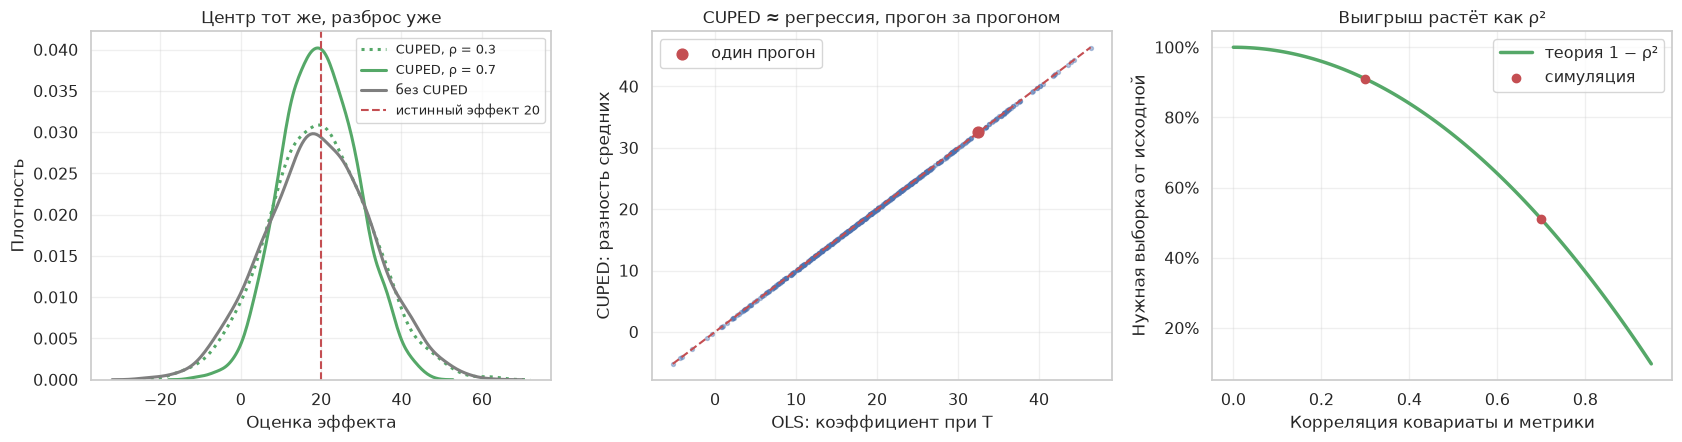

In [8]:
CUPED_CONFIG = {'n_simulations': 2_000, 'sample_size': 1_000, 'effect': 20.0, 'mean': 2_000.0, 'sigma': 300.0}


def generate_metric_covariate(rng, size, corr, mean=2_000.0, sigma=300.0):
    # Метрика и ковариата с заданной корреляцией
    covariate = rng.normal(0, 1, size)
    metric = corr * covariate + np.sqrt(1 - corr ** 2) * rng.normal(0, 1, size)
    return mean + sigma * metric, mean + sigma * covariate


def cuped_pair(y_c, x_c, y_t, x_t):
    # CUPED-метрика обеих групп с общим θ и общим средним ковариаты (по строкам)
    x, y = np.hstack([x_c, x_t]), np.hstack([y_c, y_t])
    xc = x - x.mean(axis=1, keepdims=True)
    theta = (xc * (y - y.mean(axis=1, keepdims=True))).sum(axis=1, keepdims=True) / (xc ** 2).sum(axis=1, keepdims=True)
    x_mean = x.mean(axis=1, keepdims=True)
    return y_c - theta * (x_c - x_mean), y_t - theta * (x_t - x_mean)


def ols_effect(y_c, x_c, y_t, x_t):
    # Коэффициент при T в регрессии Y ~ 1 + T + X (наклон по X общий для групп)
    def centered(a):
        return a - a.mean(axis=1, keepdims=True)
    slope = ((centered(x_c) * centered(y_c)).sum(axis=1) + (centered(x_t) * centered(y_t)).sum(axis=1)) / \
            ((centered(x_c) ** 2).sum(axis=1) + (centered(x_t) ** 2).sum(axis=1))
    return (y_t.mean(axis=1) - y_c.mean(axis=1)) - slope * (x_t.mean(axis=1) - x_c.mean(axis=1))


def diff_se(a, b):
    return b.mean(axis=1) - a.mean(axis=1), np.sqrt(a.var(axis=1, ddof=1) / a.shape[1] + b.var(axis=1, ddof=1) / b.shape[1])


size = (CUPED_CONFIG['n_simulations'], CUPED_CONFIG['sample_size'])
cuped_rows, cuped_est = [], {}
for rho, seed in ((0.3, 1), (0.7, 2)):
    rng = np.random.default_rng(seed)
    y_c, x_c = generate_metric_covariate(rng, size, rho)
    y_t, x_t = generate_metric_covariate(rng, size, rho)
    y_e = y_t + CUPED_CONFIG['effect']
    out = {}
    for key, y_test in (('aa', y_t), ('ab', y_e)):
        c_c, c_t = cuped_pair(y_c, x_c, y_test, x_t)
        out[key] = {'Без CUPED': diff_se(y_c, y_test), 'CUPED': diff_se(c_c, c_t)}
    ols = ols_effect(y_c, x_c, y_e, x_t)
    cuped_est[rho] = {'naive': out['ab']['Без CUPED'][0], 'cuped': out['ab']['CUPED'][0], 'ols': ols,
                      'se_cuped': out['ab']['CUPED'][1]}
    c_c, _ = cuped_pair(y_c, x_c, y_e, x_t)
    cuped_rows.append({
        'ρ': rho,
        'Var CUPED / Var Y': c_c.var(axis=1).mean() / y_c.var(axis=1).mean(),
        '1 − ρ²': 1 - rho ** 2,
        'оценка без CUPED': out['ab']['Без CUPED'][0].mean(),
        'оценка CUPED': out['ab']['CUPED'][0].mean(),
        'оценка OLS': ols.mean(),
        'SE Монте-Карло для CUPED': out['ab']['CUPED'][0].std() / np.sqrt(size[0]),
        'SD без CUPED': out['ab']['Без CUPED'][0].std(),
        'SD CUPED': out['ab']['CUPED'][0].std(),
        'α CUPED': np.mean(z_pvalue(*out['aa']['CUPED']) < ALPHA),
        'мощность без CUPED': np.mean(z_pvalue(*out['ab']['Без CUPED']) < ALPHA),
        'мощность CUPED': np.mean(z_pvalue(*out['ab']['CUPED']) < ALPHA),
    })
cuped_table = pd.DataFrame(cuped_rows).set_index('ρ')
print(f"Истинный эффект: {CUPED_CONFIG['effect']:.0f}")
print(cuped_table.round(3).T.to_string())
one = cuped_est[0.7]
print(f"\nОдин прогон (ρ = 0.7): CUPED {one['cuped'][0]:.1f}, OLS {one['ols'][0]:.1f}, SE {one['se_cuped'][0]:.1f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for rho, style in ((0.3, ':'), (0.7, '-')):
    sns.kdeplot(cuped_est[rho]['cuped'], ax=axes[0], color=GREEN, linestyle=style, linewidth=2.2, label=f'CUPED, ρ = {rho}')
sns.kdeplot(cuped_est[0.7]['naive'], ax=axes[0], color=GRAY, linewidth=2.2, label='без CUPED')
axes[0].axvline(CUPED_CONFIG['effect'], color=RED, ls='--', label='истинный эффект 20')
axes[0].set_xlabel('Оценка эффекта')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Центр тот же, разброс уже')
axes[0].legend(fontsize=9)
axes[1].scatter(cuped_est[0.7]['ols'][:500], cuped_est[0.7]['cuped'][:500], s=8, alpha=0.4, color=BLUE)
axes[1].scatter(cuped_est[0.7]['ols'][:1], cuped_est[0.7]['cuped'][:1], s=60, color=RED, label='один прогон')
lims = [cuped_est[0.7]['ols'][:500].min(), cuped_est[0.7]['ols'][:500].max()]
axes[1].plot(lims, lims, color=RED, ls='--')
axes[1].set_xlabel('OLS: коэффициент при T')
axes[1].set_ylabel('CUPED: разность средних')
axes[1].set_title('CUPED ≈ регрессия, прогон за прогоном')
axes[1].legend()
rhos = np.linspace(0, 0.95, 100)
axes[2].plot(rhos, 1 - rhos ** 2, color=GREEN, linewidth=2.5, label='теория 1 − ρ²')
axes[2].scatter(cuped_table.index, cuped_table['Var CUPED / Var Y'], color=RED, zorder=3, label='симуляция')
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[2].set_xlabel('Корреляция ковариаты и метрики')
axes[2].set_ylabel('Нужная выборка от исходной')
axes[2].set_title('Выигрыш растёт как ρ²')
axes[2].legend()
plt.tight_layout()
plt.show()

* **Несмещённость.** Средняя оценка по 2 000 прогонам ≈ 20 и без CUPED, и с ним, и в регрессии: отличие от 20 в пределах двух SE Монте-Карло (≈ 0.2–0.3). В отдельном прогоне оценка легко уходит от 20 на две SE (≈ ±19 при ρ = 0.7) — это шум, а не смещение. CUPED и OLS при этом почти совпадают: точки лежат на диагонали.
* **Дисперсия** падает до $1 - \rho^2$: при ρ = 0.3 это −9% (почти ничего), при ρ = 0.7 — −51%. При той же выборке мощность растёт с ≈ 0.30 до ≈ 0.53; чтобы без CUPED получить столько же, нужна вдвое большая выборка.
* **A/A** с CUPED даёт α ≈ 4–5%: на 2 000 прогонах шум самой доли — около ±1 п.п.
* Регрессия обобщает CUPED: несколько ковариат — это просто регрессия с несколькими признаками.
* Новым пользователям без предпериода ковариату заполняют одним правилом в обеих группах (нулём или средним): оценка остаётся несмещённой, выигрыша на них нет.

### [Линеаризация](https://doi.org/10.1145/3159652.3159699)

Метрика отношения (CTR, средний чек) — это отношение сумм, её наблюдения — показы или заказы, а не пользователи. Единица анализа не совпадает с единицей рандомизации (блок 1), и наивный тест врёт. Дисперсию отношения считает дельта-метод. CUPED с ним тоже совместим (Deng et al., 2013, — ratio-метрики через дельта-метод), но линеаризация ([Budylin et al., 2018](https://doi.org/10.1145/3159652.3159699)) делает это проще: превращает отношение в пользовательскую метрику

$$
Lin(u) = Y(u) - \mathcal{R}^{ctrl} X(u),
$$

и дальше работает любой метод для пользовательских метрик — t-тест, CUPED, стратификация. Сама линеаризация дисперсию не снижает: её p-value совпадают с дельта-методом. Проверим на CTR с ростом на 5%.

                              Ошибка I рода  Мощность
По показам, клики независимы          0.191     0.586
Среднее CTR пользователей             0.048     0.260
Дельта-метод                          0.052     0.340
Линеаризация                          0.052     0.346
Линеаризация с весами                 0.046     0.384
Линеаризация + CUPED                  0.048     0.462


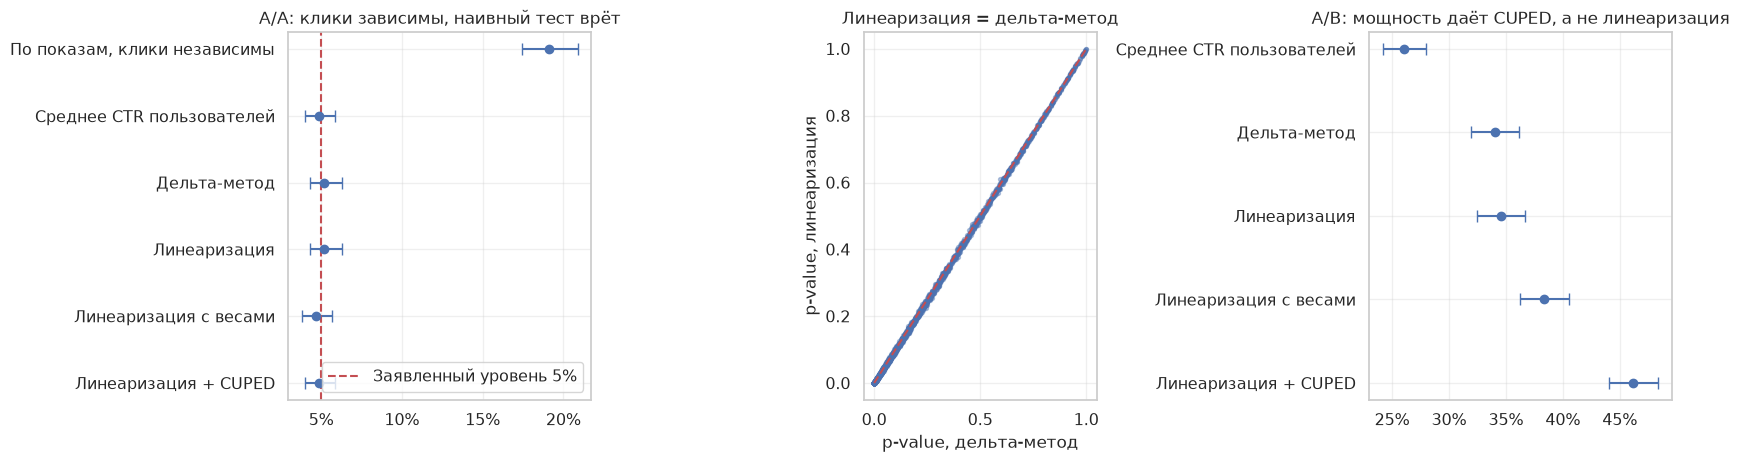

In [9]:
LIN_CONFIG = {
    "n_simulations": 2_000,
    "n_users": 3_000,
    "uplift": 0.05,  # рост CTR на 5%
}


def generate_ctr_data(rng: np.random.Generator, size: tuple[int, int], uplift: float = 0.0) -> dict[str, np.ndarray]:
    """Генерирует просмотры и клики пользователей до и во время эксперимента."""
    activity = rng.gamma(1.0, 12.0, size)  # у пользователей разная активность
    ctr = rng.beta(2, 18, size) * np.clip(1.6 - 0.03 * activity, 0.4, 1.6)  # и разная склонность кликать
    views_pre = 1 + rng.poisson(activity)
    views = 1 + rng.poisson(activity)
    return {
        'views_pre': views_pre,
        'clicks_pre': rng.binomial(views_pre, ctr),
        'views': views,
        'clicks': rng.binomial(views, np.minimum(ctr * (1 + uplift), 1)),
    }


def ratio_delta_var(views: np.ndarray, clicks: np.ndarray) -> np.ndarray:
    """Считает дисперсию ratio-метрики дельта-методом по пользовательским суммам."""
    n = views.shape[1]
    mean_x, mean_y = views.mean(axis=1, keepdims=True), clicks.mean(axis=1, keepdims=True)
    ratio = mean_y / mean_x
    return ((clicks - ratio * views) ** 2).sum(axis=1) / (n - 1) / (n * mean_x[:, 0] ** 2)


def ratio_tests(control: dict[str, np.ndarray], pilot: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    """Возвращает p-value разных критериев для метрики отношения."""
    x_c, y_c, x_t, y_t = control['views'], control['clicks'], pilot['views'], pilot['clicks']
    r_c = y_c.sum(axis=1, keepdims=True) / x_c.sum(axis=1, keepdims=True)
    r_t = y_t.sum(axis=1, keepdims=True) / x_t.sum(axis=1, keepdims=True)
    delta = (r_t - r_c)[:, 0]

    # Клики как независимые испытания: типичная ошибка
    se_naive = np.sqrt(r_c[:, 0] * (1 - r_c[:, 0]) / x_c.sum(axis=1) + r_t[:, 0] * (1 - r_t[:, 0]) / x_t.sum(axis=1))
    se_delta = np.sqrt(ratio_delta_var(x_c, y_c) + ratio_delta_var(x_t, y_t))

    lin_c, lin_t = y_c - r_c * x_c, y_t - r_c * x_t

    w_c, w_t = np.sqrt(x_c), np.sqrt(x_t)
    r_rew = ((w_c * y_c / x_c).sum(axis=1) / w_c.sum(axis=1))[:, None]
    rew_c, rew_t = (y_c - r_rew * x_c) / w_c, (y_t - r_rew * x_t) / w_t

    # CUPED поверх линеаризации: ковариата — та же линеаризованная метрика на предпериоде
    r_pre = control['clicks_pre'].sum(axis=1, keepdims=True) / control['views_pre'].sum(axis=1, keepdims=True)
    cov_c = control['clicks_pre'] - r_pre * control['views_pre']
    cov_t = pilot['clicks_pre'] - r_pre * pilot['views_pre']
    pooled_lin, pooled_cov = np.hstack([lin_c, lin_t]), np.hstack([cov_c, cov_t])
    centered_cov = pooled_cov - pooled_cov.mean(axis=1, keepdims=True)
    theta = ((pooled_lin * centered_cov).sum(axis=1) / (centered_cov ** 2).sum(axis=1))[:, None]

    return {
        'По показам, клики независимы': z_pvalue(delta, se_naive),
        'Среднее CTR пользователей': stats.ttest_ind(y_t / x_t, y_c / x_c, axis=1).pvalue,
        'Дельта-метод': z_pvalue(delta, se_delta),
        'Линеаризация': stats.ttest_ind(lin_t, lin_c, axis=1).pvalue,
        'Линеаризация с весами': stats.ttest_ind(rew_t, rew_c, axis=1).pvalue,
        'Линеаризация + CUPED': stats.ttest_ind(lin_t - theta * cov_t, lin_c - theta * cov_c, axis=1).pvalue,
    }


def simulate_ratio(n_simulations: int, n_users: int, uplift: float, batch: int = 200) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает p-value всех критериев."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {'aa': {}, 'ab': {}}
    for _ in range(n_simulations // batch):
        for key, effect in (('aa', 0.0), ('ab', uplift)):
            control = generate_ctr_data(rng, (batch, n_users))
            pilot = generate_ctr_data(rng, (batch, n_users), effect)
            for name, pvalues in ratio_tests(control, pilot).items():
                result[key].setdefault(name, []).append(pvalues)
    return {key: {name: np.concatenate(values) for name, values in row.items()} for key, row in result.items()}


ratio_pvalues = simulate_ratio(**LIN_CONFIG)
print(pd.DataFrame({
    'Ошибка I рода': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['aa'].items()},
    'Мощность': {name: np.mean(p < ALPHA) for name, p in ratio_pvalues['ab'].items()},
}).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1.3]})
plot_rates(axes[0], {name: p < ALPHA for name, p in ratio_pvalues['aa'].items()}, 'A/A: клики зависимы, наивный тест врёт')
axes[1].scatter(ratio_pvalues['ab']['Дельта-метод'], ratio_pvalues['ab']['Линеаризация'], s=8, alpha=0.4, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=RED, linestyle='--')
axes[1].set_title('Линеаризация = дельта-метод')
axes[1].set_xlabel('p-value, дельта-метод')
axes[1].set_ylabel('p-value, линеаризация')
correct = [name for name in ratio_pvalues['ab'] if name != 'По показам, клики независимы']
plot_rates(axes[2], {name: ratio_pvalues['ab'][name] < ALPHA for name in correct}, 'A/B: мощность даёт CUPED, а не линеаризация', None)
plt.tight_layout()
plt.show()

* Если считать показы независимыми, ложных срабатываний ≈ 19% вместо 5%.
* Линеаризация и дельта-метод совпадают: точки на среднем графике лежат на диагонали, мощность ≈ 0.34.
* Среднее CTR пользователей — корректный тест **другой метрики**: каждый пользователь весит одинаково. Мощность другая (≈ 0.26).
* Выигрыш даёт CUPED поверх линеаризации: мощность ≈ 0.46.

Эффект на линеаризованной метрике равен $\bar X^{test}(\mathcal{R}^{test} - \mathcal{R}^{ctrl})$: чтобы вернуться к единицам CTR, делим на средний знаменатель теста.

### [Выбросы](https://habr.com/ru/companies/avito/articles/571094/)

Выбросы раздувают дисперсию, и хочется «убрать верхний 1%». Сравним способы на скошенной выручке: среднее 1000, в A/B выручка растёт у всех на 15%, истинный эффект 150.

Истинный эффект на всю аудиторию: 150
                                   Ошибка I рода  Мощность  Оценка эффекта  SD оценки  Средняя SE
Без очистки                                0.048     0.603         149.818     68.609      68.049
Свой порог в каждой группе                 0.083     0.699         137.360     61.150      54.037
Свой порог + поправка SE                   0.050     0.621         137.360     61.150      60.943
Общий порог по тесту и контролю            0.054     0.536         110.578     54.179      53.817
Порог по контролю                          0.054     0.466          98.138     51.777      51.878
Порог предпериода к метрике теста          0.056     0.518         104.315     51.841      51.800
Исключение по выручке до теста             0.048     0.603         147.653     67.386      66.918
Винзоризация порогом предпериода           0.051     0.623         132.991     59.072      58.753


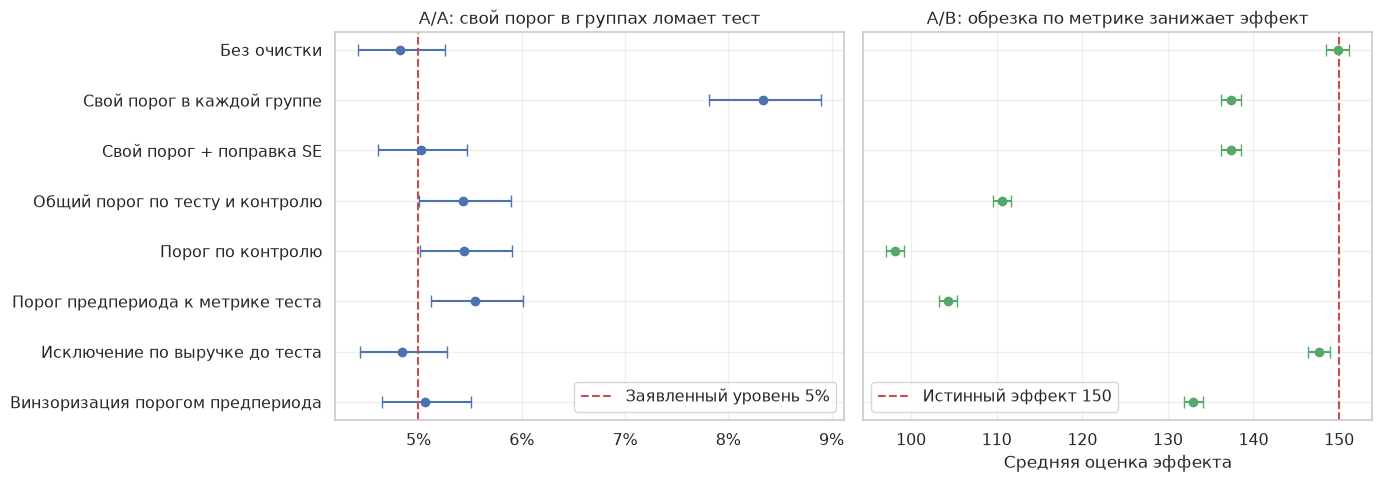

In [10]:
OUTLIER_CONFIG = {
    "n_simulations": 10_000,
    "sample_size": 1_000,
    "tail_share": 0.01,
    "lift": 1.15,  # эффект: выручка каждого пользователя выросла на 15%
}
OUTLIER_TRUE_EFFECT = 1_000 * (OUTLIER_CONFIG["lift"] - 1)


def generate_revenue(rng: np.random.Generator, size: tuple[int, int], lift: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """Генерирует выручку пользователя до и во время эксперимента. Средняя выручка до эксперимента равна 1000."""
    activity = rng.gamma(2, 500, size)  # постоянная часть: активные пользователи тратят больше в оба периода
    return activity * rng.exponential(1, size), lift * activity * rng.exponential(1, size)


def clean_and_compare(pre_c: np.ndarray, y_c: np.ndarray, pre_t: np.ndarray, y_t: np.ndarray,
                      tail_share: float) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """Применяет способы очистки и для каждого возвращает оценку эффекта и её стандартную ошибку."""
    level = 1 - tail_share
    n = y_c.shape[1]
    q_c = np.quantile(y_c, level, axis=1, keepdims=True)
    q_t = np.quantile(y_t, level, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), level, axis=1, keepdims=True)
    q_pre = np.quantile(np.hstack([pre_c, pre_t]), level, axis=1, keepdims=True)

    def compare(x_c, mask_c, x_t, mask_t):
        mean_c, var_c, n_c = masked_mean_var(x_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(x_t, mask_t)
        return mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)

    everyone = np.ones_like(y_c, dtype=bool)
    per_group = compare(y_c, y_c <= q_c, y_t, y_t <= q_t)
    # SE усечённого среднего, учитывающая случайность порога: дисперсия винзоризованной метрики / (1 - доля)^2
    yuen_var = (np.minimum(y_c, q_c).var(axis=1, ddof=1) + np.minimum(y_t, q_t).var(axis=1, ddof=1)) / level ** 2
    return {
        'Без очистки': compare(y_c, everyone, y_t, everyone),
        'Свой порог в каждой группе': per_group,
        'Свой порог + поправка SE': (per_group[0], np.sqrt(yuen_var / n)),
        'Общий порог по тесту и контролю': compare(y_c, y_c <= q_pooled, y_t, y_t <= q_pooled),
        'Порог по контролю': compare(y_c, y_c <= q_c, y_t, y_t <= q_c),
        'Порог предпериода к метрике теста': compare(y_c, y_c <= q_pre, y_t, y_t <= q_pre),
        'Исключение по выручке до теста': compare(y_c, pre_c <= q_pre, y_t, pre_t <= q_pre),
        'Винзоризация порогом предпериода': compare(np.minimum(y_c, q_pre), everyone, np.minimum(y_t, q_pre), everyone),
    }


def simulate_outliers(n_simulations: int, sample_size: int, tail_share: float, lift: float,
                      batch: int = 500) -> dict[str, dict[str, np.ndarray]]:
    """Прогоняет A/A и A/B и собирает оценки эффекта, SE и решения по каждому способу очистки."""
    rng = np.random.default_rng(42)
    result: dict[str, dict[str, list]] = {}
    for _ in range(n_simulations // batch):
        for key, group_lift in (('aa', 1.0), ('ab', lift)):
            pre_c, y_c = generate_revenue(rng, (batch, sample_size))
            pre_t, y_t = generate_revenue(rng, (batch, sample_size), group_lift)
            for name, (delta, se) in clean_and_compare(pre_c, y_c, pre_t, y_t, tail_share).items():
                row = result.setdefault(name, {'aa': [], 'ab': [], 'delta': [], 'se': []})
                row[key].append(z_pvalue(delta, se) < ALPHA)
                if key == 'ab':
                    row['delta'].append(delta)
                    row['se'].append(se)
    return {name: {key: np.concatenate(values) for key, values in row.items()} for name, row in result.items()}


outlier_results = simulate_outliers(**OUTLIER_CONFIG)
outlier_table = pd.DataFrame({
    name: {
        'Ошибка I рода': row['aa'].mean(),
        'Мощность': row['ab'].mean(),
        'Оценка эффекта': row['delta'].mean(),
        'SD оценки': row['delta'].std(),
        'Средняя SE': row['se'].mean(),
    } for name, row in outlier_results.items()
}).T
print(f'Истинный эффект на всю аудиторию: {OUTLIER_TRUE_EFFECT:.0f}')
print(outlier_table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_rates(axes[0], {name: row['aa'] for name, row in outlier_results.items()}, 'A/A: свой порог в группах ломает тест')
names = list(outlier_results)[::-1]
axes[1].errorbar(outlier_table.loc[names, 'Оценка эффекта'], names,
                 xerr=1.96 * outlier_table.loc[names, 'SD оценки'] / np.sqrt(OUTLIER_CONFIG['n_simulations']),
                 fmt='o', color=GREEN, capsize=4)
axes[1].axvline(OUTLIER_TRUE_EFFECT, color=RED, linestyle='--', label=f'Истинный эффект {OUTLIER_TRUE_EFFECT:.0f}')
axes[1].set_title('A/B: обрезка по метрике занижает эффект')
axes[1].set_xlabel('Средняя оценка эффекта')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

* **Свой порог в каждой группе** ломает тест: α ≈ 8% вместо 5%. Порог оценён по тем же данным, его шум попадает в оценку, а SE этого не знает. Чем больше отрезаем, тем хуже — см. график ниже.
* **Общий порог** чинит A/A, но не A/B: оценка ≈ 111 вместо 150. Удаление по метрике **во время теста** — отбор по тому, на что повлияло воздействие.
* **Корректно:** исключать по поведению **до** теста (оценка ≈ 148, но на оставшихся) или **винзоризовать порогом предпериода** $\min(Y, q_{pre})$: никого не выкидываем, α ≈ 5%, мощность чуть выше, смещение понятное — эффект на ограниченную сверху метрику.

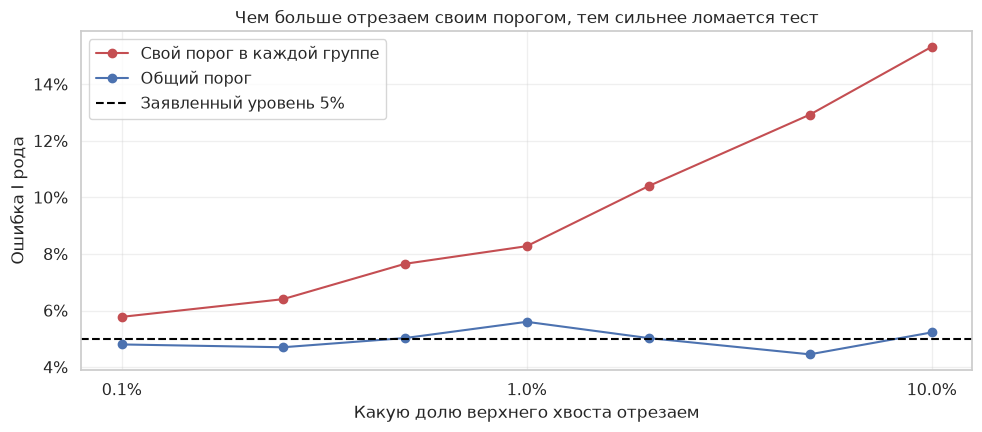

In [11]:
rng = np.random.default_rng(42)
tail_shares = np.array([0.001, 0.0025, 0.005, 0.01, 0.02, 0.05, 0.1])
per_group_fpr, pooled_fpr = [], []
for share in tail_shares:
    _, y_c = generate_revenue(rng, (4_000, 1_000))
    _, y_t = generate_revenue(rng, (4_000, 1_000))
    q_c = np.quantile(y_c, 1 - share, axis=1, keepdims=True)
    q_t = np.quantile(y_t, 1 - share, axis=1, keepdims=True)
    q_pooled = np.quantile(np.hstack([y_c, y_t]), 1 - share, axis=1, keepdims=True)
    for store, mask_c, mask_t in ((per_group_fpr, y_c <= q_c, y_t <= q_t), (pooled_fpr, y_c <= q_pooled, y_t <= q_pooled)):
        mean_c, var_c, n_c = masked_mean_var(y_c, mask_c)
        mean_t, var_t, n_t = masked_mean_var(y_t, mask_t)
        store.append(np.mean(z_pvalue(mean_t - mean_c, np.sqrt(var_c / n_c + var_t / n_t)) < ALPHA))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tail_shares, per_group_fpr, 'o-', color=RED, label='Свой порог в каждой группе')
ax.plot(tail_shares, pooled_fpr, 'o-', color=BLUE, label='Общий порог')
ax.axhline(ALPHA, color='black', linestyle='--', label='Заявленный уровень 5%')
ax.set_xscale('log')
ax.set_xticks([0.001, 0.01, 0.1])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.1%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_xlabel('Какую долю верхнего хвоста отрезаем')
ax.set_ylabel('Ошибка I рода')
ax.set_title('Чем больше отрезаем своим порогом, тем сильнее ломается тест')
ax.legend()
plt.tight_layout()
plt.show()

## Итоги: что идёт в дизайн-док

1. Гипотеза, единица рандомизации и единица анализа.
2. Метрики и их роли: качество данных → OEC → guardrail → диагностические; поправки по правилу запуска.
3. α (из вердикта встречи 1), мощность, сторонность, MDE в явных единицах (п.п. или %), сплит.
4. $N$ из одной формулы, длительность в целых неделях, правило остановки.
5. Ускорение: какая ковариата для CUPED, какие страты, как обращаемся с выбросами — всё фиксируем **до** старта.

Шаблон — `design_doc_template.md`, заполняем его в `practice.ipynb` на данных чекаута.

### Источники

* Kohavi, Tang, Xu. *Trustworthy Online Controlled Experiments*, 2020 — главы о метриках, SRM и снижении дисперсии.
* [Deng et al., 2013. CUPED](https://doi.org/10.1145/2433396.2433413).
* [Budylin et al., 2018. Линеаризация ratio-метрик](https://doi.org/10.1145/3159652.3159699).
* [Schultzberg et al., 2024. Risk-aware product decisions in A/B tests with multiple metrics (Spotify)](https://arxiv.org/abs/2402.11609).
* [Dmitriev et al., 2017. Metric interpretation pitfalls](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf).
* X5 Tech: [стратификация](https://habr.com/ru/companies/X5Tech/articles/596279/), [CUPED](https://habr.com/ru/companies/X5Tech/articles/780270/); Авито: [выбросы](https://habr.com/ru/companies/avito/articles/571094/).